# Install & Import Liberaries

In [ ]:
%%capture
!pip install gym==0.26.2 pyglet==2.0.10 pygame==2.5.2 numpy==1.26.4 PyQt5 opencv-python

In [ ]:
import gym
import time
import matplotlib.pyplot as plt
from IPython import display
import numpy as np
import torch
from torch import nn
import torch.nn.functional as F
from torch import optim
from torch.distributions import Categorical
from torchvision import transforms
import torchvision
from PIL import Image
from IPython.display import clear_output

# RL helpers

In [ ]:
def show_img_obs(frame, rm_pre=False):
    if rm_pre:
        display.clear_output(wait=True)

    if isinstance(frame, torch.Tensor):
        frame = frame.squeeze(0).permute(1, 2, 0).cpu().numpy()

    plt.figure(figsize=(10, 7))
    plt.imshow(frame)
    plt.axis('off')
    display.display(plt.gcf())
    plt.close()

def show_three_images(prev_img, curr_img, result_img, rm_pre=False):
    if rm_pre:
        display.clear_output(wait=True)

    def process_img(img):
        if isinstance(img, torch.Tensor):
            img = img.squeeze(0).permute(1, 2, 0).cpu().numpy()
        return img

    images = [process_img(prev_img), process_img(curr_img), process_img(result_img)]
    titles = ['Previous', 'Current', 'Result']

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    for ax, img, title in zip(axes, images, titles):
        ax.imshow(img)
        ax.set_title(title)
        ax.axis('off')

    display.display(fig)
    plt.close(fig)

def get_batch_img_obs(obs_img, b_size, transform):
    trans_imgs = []
    for _ in range(b_size):
        trans_img = transform(obs_img)
        trans_imgs.append(trans_img)
    return torch.stack(trans_imgs)

def get_img_obs(env):
    frame = env.render()
    if frame.dtype != np.float32:
        frame = frame.astype(np.float32)
    frame /= 255.0
    frame = np.transpose(frame, (2, 0, 1))
    frame = torch.from_numpy(frame)

    return frame

def get_image_diff(curr_img, prev_img):
    curr_img = curr_img.float()
    prev_img = prev_img.float()

    if curr_img.shape != prev_img.shape:
        raise ValueError(f"Image shapes do not match: {curr_img.shape} vs {prev_img.shape}")

    diff = curr_img - prev_img

    abs_max = torch.max(torch.abs(diff))
    epsilon = 1e-8

    transformed = (diff / (abs_max + epsilon) + 1) / 2
    transformed = torch.clamp(transformed, 0, 1)
    return transformed


def live_plot(metrics):
    clear_output(wait=True)
    fig, axes = plt.subplots(1, 4, figsize=(20, 6))

    # Epoch indices for plotting (starting from 1)
    epochs = range(1, len(metrics["train_avg_rewards"]) + 1)

    # Plot Average Rewards (Train & Eval)
    axes[0].plot(epochs, metrics["train_avg_rewards"], '-o', label="Train Avg Rewards")
    axes[0].plot(epochs, metrics["eval_avg_rewards"], '-o', color='orange', label="Eval Avg Rewards")
    axes[0].set_title("Average Rewards")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Average Reward")
    axes[0].legend()
    axes[0].grid(True)

    # Plot std Rewards (Train & Eval)
    axes[1].plot(epochs, metrics["train_std_rewards"], '-o', label="Train Std Rewards")
    axes[1].plot(epochs, metrics["eval_std_rewards"], '-o', color='orange', label="Eval Std Rewards")
    axes[1].set_title("Std Rewards")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Std Reward")
    axes[1].legend()
    axes[1].grid(True)

    # Plot Average Episode Lengths (Train & Eval)
    axes[2].plot(epochs, metrics["train_avg_epi_lens"], '-o', label="Train Avg Episode Length")
    axes[2].plot(epochs, metrics["eval_avg_epi_len"], '-o', color='orange', label="Eval Avg Episode Length")
    axes[2].set_title("Average Episode Length")
    axes[2].set_xlabel("Epoch")
    axes[2].set_ylabel("Episode Length")
    axes[2].legend()
    axes[2].grid(True)

    # Plot Accuracy (Train & Eval)
    axes[3].plot(epochs, metrics["train_acc"], '-o', label="Train Accuracy")
    axes[3].plot(epochs, metrics["eval_acc"], '-o', color='orange', label="Eval Accuracy")
    axes[3].set_title("Accuracy")
    axes[3].set_xlabel("Epoch")
    axes[3].set_ylabel("Accuracy (%)")
    axes[3].legend()
    axes[3].grid(True)

    plt.tight_layout()
    plt.show()


def evaluate_cnn_diff_policy(agent, env, n_eval_episode, threshold, transform):
    agent.eval()
    total_rewards = []
    epi_lengths = []
    n_successes = 0

    for _ in range(n_eval_episode):
        obs, _ = env.reset()
        done = False
        total_reward = 0
        epi_len = 0
        while not done:
            with torch.no_grad():
                if epi_len == 0:
                    epi_len += 1
                    prev_img_obs = get_img_obs(env)
                    continue

                epi_len += 1

                # use diff = img_obs(t) - img_obs(t-1)
                curr_img_obs = get_img_obs(env)
                img_diff = get_image_diff(curr_img_obs, prev_img_obs)
                prev_img_obs = curr_img_obs

                # apply valid transform
                img_diff = transform(img_diff)

                # sample from policy
                action_probs = agent(img_diff)
            action = torch.argmax(action_probs, dim=1).item()

            obs, reward, done, truncated, _ = env.step(action)
            total_reward += reward

            if truncated:
                done = True

        total_rewards.append(total_reward)
        epi_lengths.append(epi_len)
        if total_reward >= threshold:
            n_successes += 1

    agent.train()

    eval_acc = (n_successes / n_eval_episode) * 100
    eval_avg_rewards = np.mean(total_rewards)
    eval_std_rewards = np.std(total_rewards)
    eval_avg_epi_len = np.mean(epi_lengths)

    return {
        "eval_acc": eval_acc,
        "eval_avg_rewards": eval_avg_rewards,
        "eval_std_rewards": eval_std_rewards,
        "eval_avg_epi_len": eval_avg_epi_len
    }

# Testing The env

🚀 Environment Information:
🎮 Possible Actions: [0, 1]
🏆 Reward Range: (-inf, inf)
prev image shape: torch.Size([3, 400, 600])
curr image shape: torch.Size([3, 400, 600])
diff image shape: torch.Size([3, 400, 600])
batch shape: torch.Size([32, 3, 128, 128])


/usr/local/lib/python3.11/dist-packages/gym/utils/passive_env_checker.py:233: DeprecationWarning: `np.bool8` is a deprecated alias for `np.bool_`.  (Deprecated NumPy 1.24)
  if not isinstance(terminated, (bool, np.bool8)):


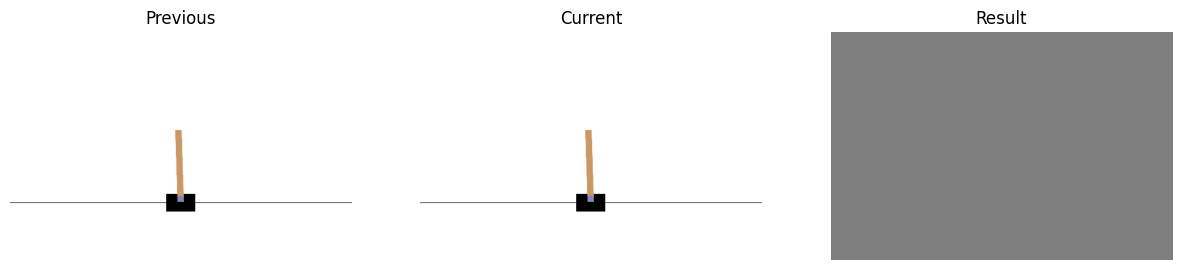

prev image shape: torch.Size([3, 400, 600])
curr image shape: torch.Size([3, 400, 600])
diff image shape: torch.Size([3, 400, 600])
batch shape: torch.Size([32, 3, 128, 128])


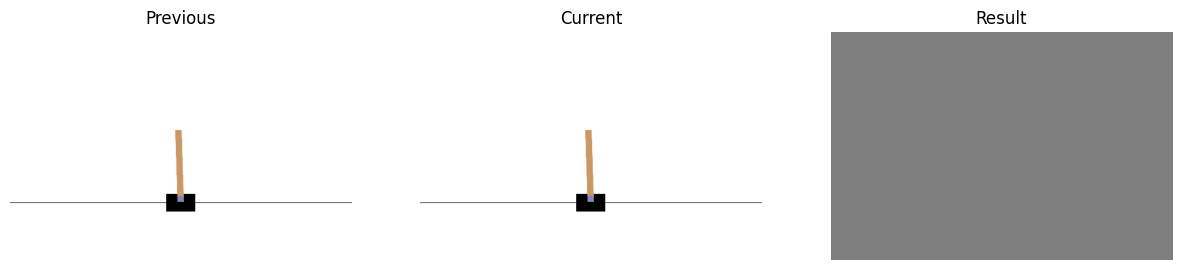

prev image shape: torch.Size([3, 400, 600])
curr image shape: torch.Size([3, 400, 600])
diff image shape: torch.Size([3, 400, 600])
batch shape: torch.Size([32, 3, 128, 128])


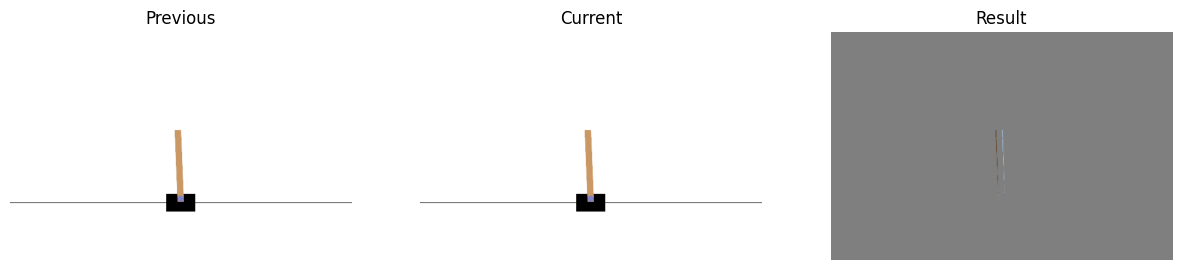

prev image shape: torch.Size([3, 400, 600])
curr image shape: torch.Size([3, 400, 600])
diff image shape: torch.Size([3, 400, 600])
batch shape: torch.Size([32, 3, 128, 128])


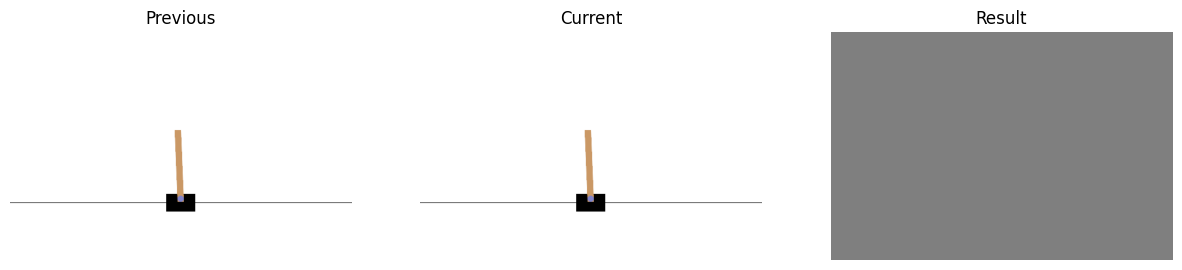

prev image shape: torch.Size([3, 400, 600])
curr image shape: torch.Size([3, 400, 600])
diff image shape: torch.Size([3, 400, 600])
batch shape: torch.Size([32, 3, 128, 128])


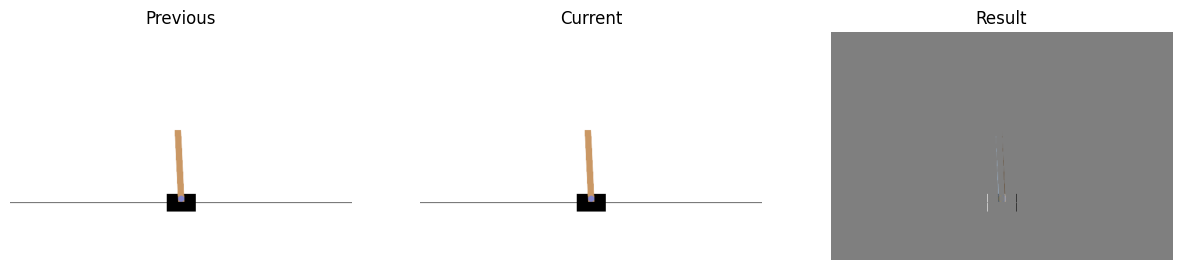

prev image shape: torch.Size([3, 400, 600])
curr image shape: torch.Size([3, 400, 600])
diff image shape: torch.Size([3, 400, 600])
batch shape: torch.Size([32, 3, 128, 128])


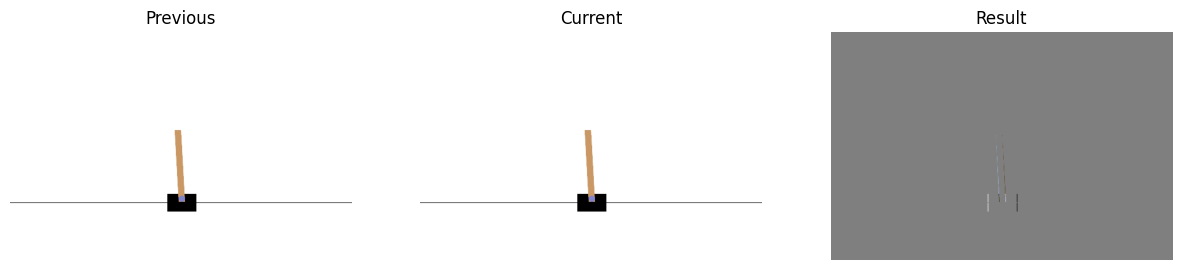

prev image shape: torch.Size([3, 400, 600])
curr image shape: torch.Size([3, 400, 600])
diff image shape: torch.Size([3, 400, 600])
batch shape: torch.Size([32, 3, 128, 128])


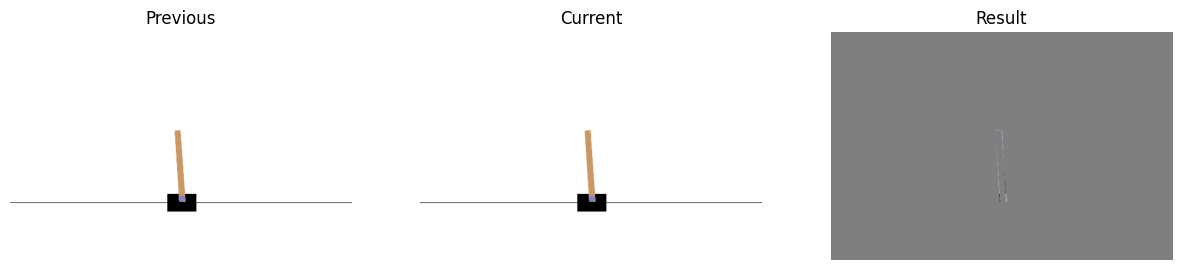

prev image shape: torch.Size([3, 400, 600])
curr image shape: torch.Size([3, 400, 600])
diff image shape: torch.Size([3, 400, 600])
batch shape: torch.Size([32, 3, 128, 128])


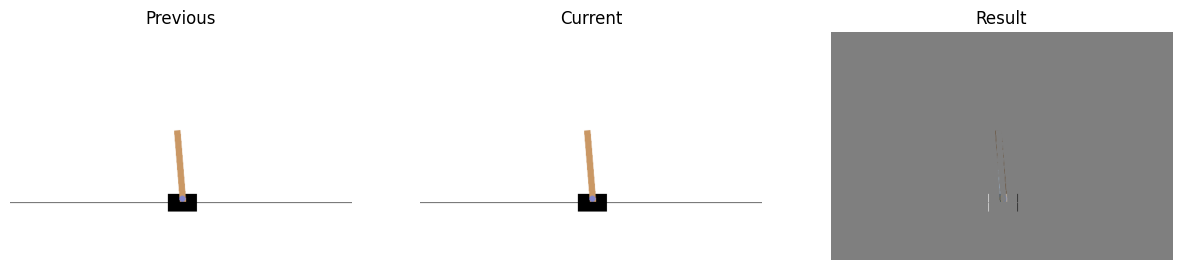

prev image shape: torch.Size([3, 400, 600])
curr image shape: torch.Size([3, 400, 600])
diff image shape: torch.Size([3, 400, 600])
batch shape: torch.Size([32, 3, 128, 128])


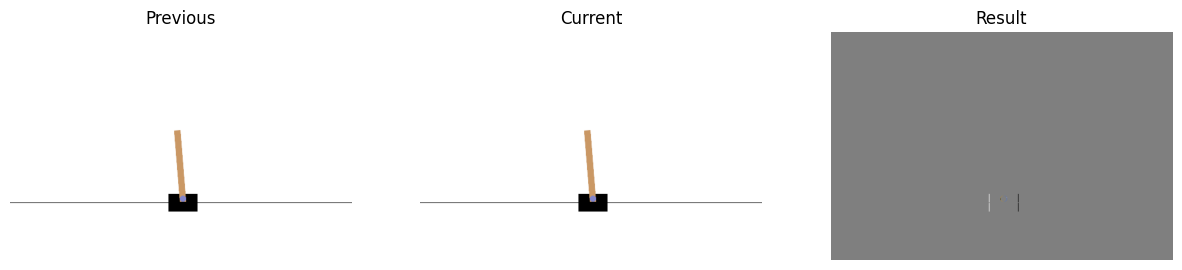

prev image shape: torch.Size([3, 400, 600])
curr image shape: torch.Size([3, 400, 600])
diff image shape: torch.Size([3, 400, 600])
batch shape: torch.Size([32, 3, 128, 128])


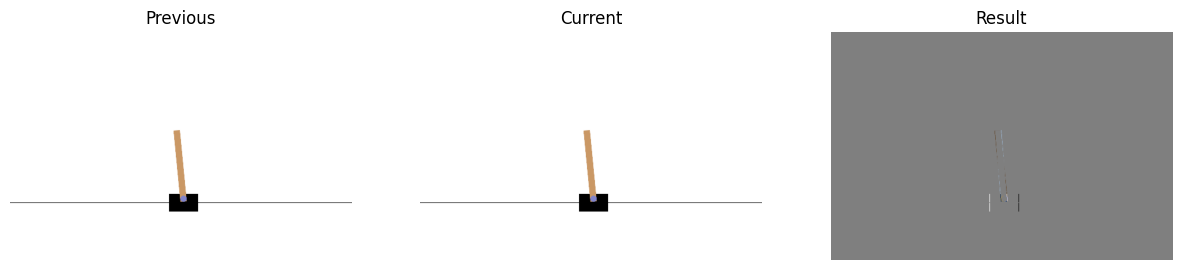

prev image shape: torch.Size([3, 400, 600])
curr image shape: torch.Size([3, 400, 600])
diff image shape: torch.Size([3, 400, 600])
batch shape: torch.Size([32, 3, 128, 128])


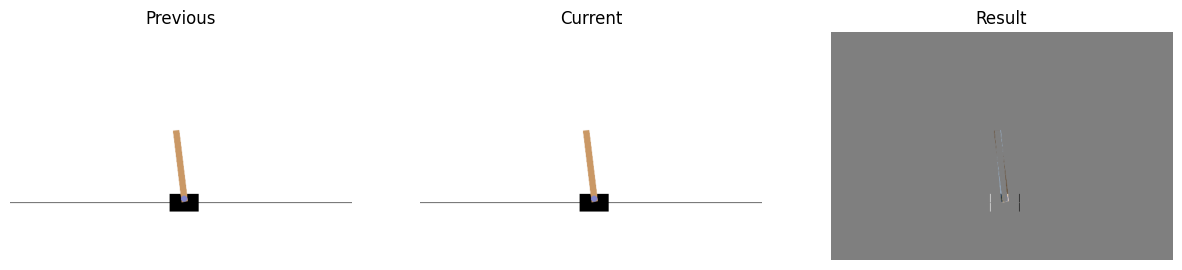

prev image shape: torch.Size([3, 400, 600])
curr image shape: torch.Size([3, 400, 600])
diff image shape: torch.Size([3, 400, 600])
batch shape: torch.Size([32, 3, 128, 128])


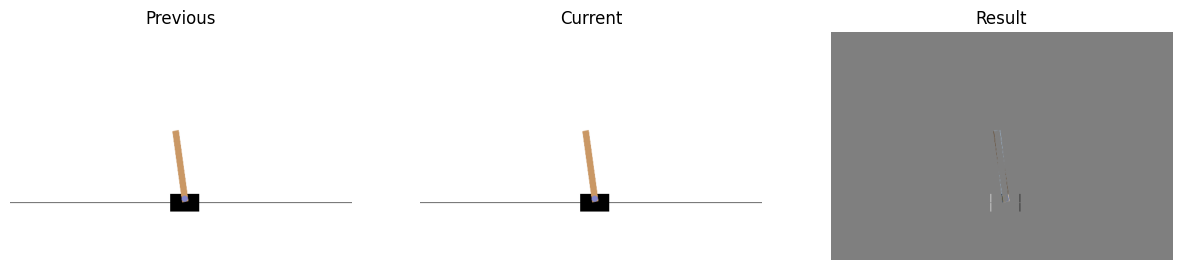

prev image shape: torch.Size([3, 400, 600])
curr image shape: torch.Size([3, 400, 600])
diff image shape: torch.Size([3, 400, 600])
batch shape: torch.Size([32, 3, 128, 128])


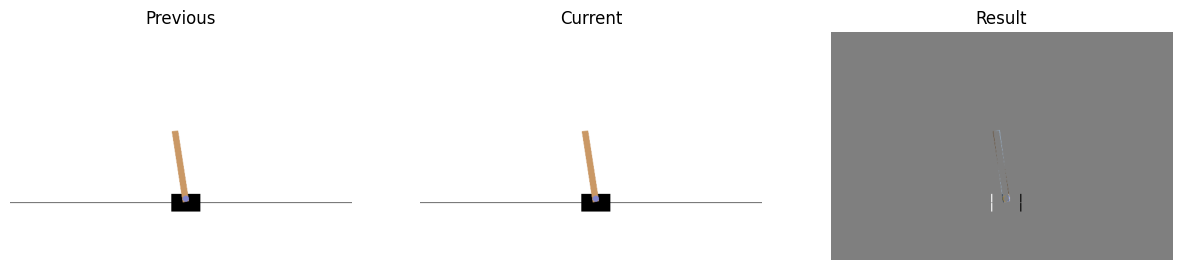

prev image shape: torch.Size([3, 400, 600])
curr image shape: torch.Size([3, 400, 600])
diff image shape: torch.Size([3, 400, 600])
batch shape: torch.Size([32, 3, 128, 128])


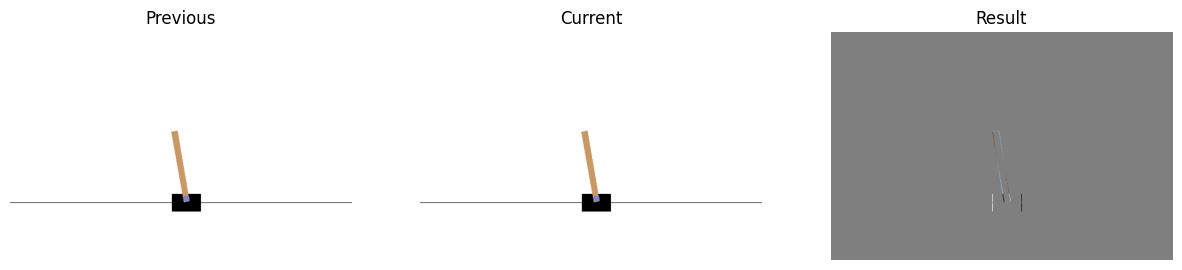

prev image shape: torch.Size([3, 400, 600])
curr image shape: torch.Size([3, 400, 600])
diff image shape: torch.Size([3, 400, 600])
batch shape: torch.Size([32, 3, 128, 128])


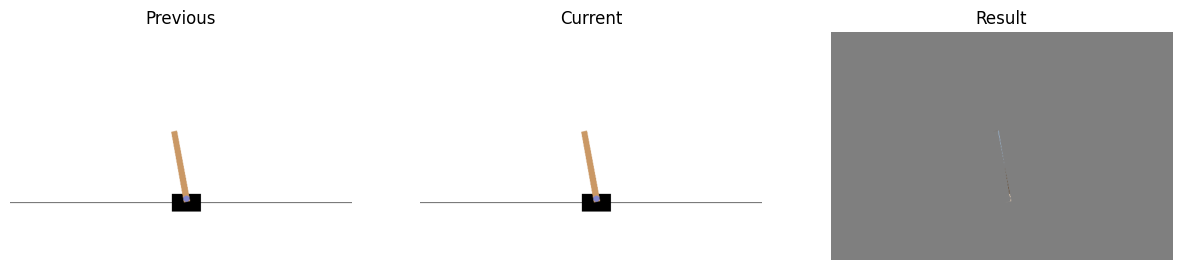

prev image shape: torch.Size([3, 400, 600])
curr image shape: torch.Size([3, 400, 600])
diff image shape: torch.Size([3, 400, 600])
batch shape: torch.Size([32, 3, 128, 128])


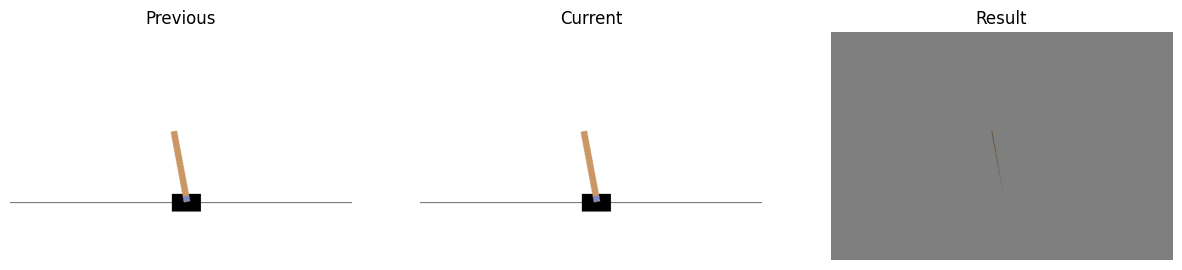

prev image shape: torch.Size([3, 400, 600])
curr image shape: torch.Size([3, 400, 600])
diff image shape: torch.Size([3, 400, 600])
batch shape: torch.Size([32, 3, 128, 128])


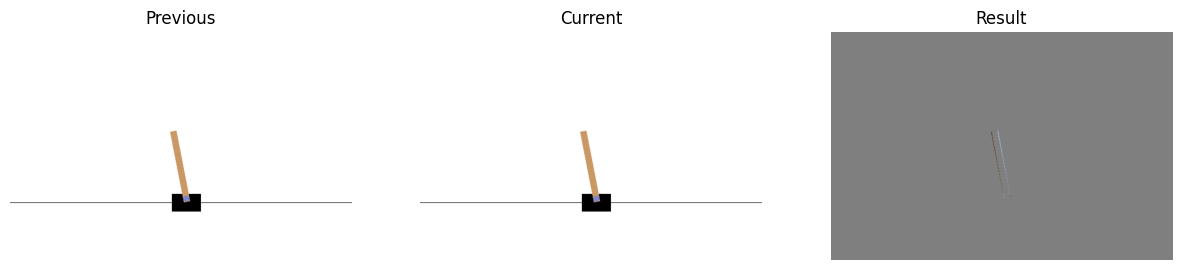

prev image shape: torch.Size([3, 400, 600])
curr image shape: torch.Size([3, 400, 600])
diff image shape: torch.Size([3, 400, 600])
batch shape: torch.Size([32, 3, 128, 128])


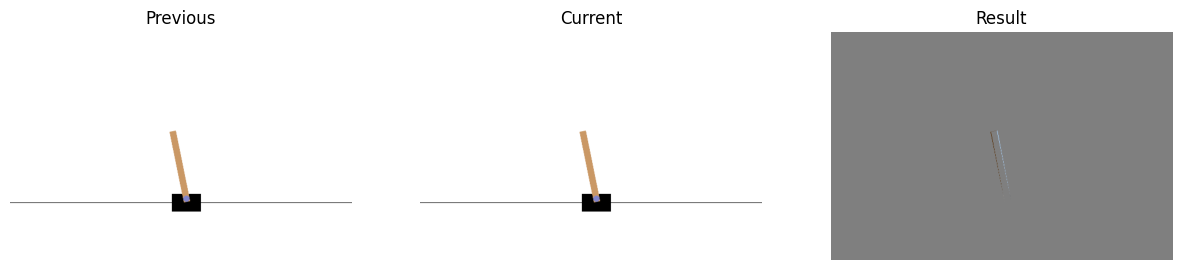

prev image shape: torch.Size([3, 400, 600])
curr image shape: torch.Size([3, 400, 600])
diff image shape: torch.Size([3, 400, 600])
batch shape: torch.Size([32, 3, 128, 128])


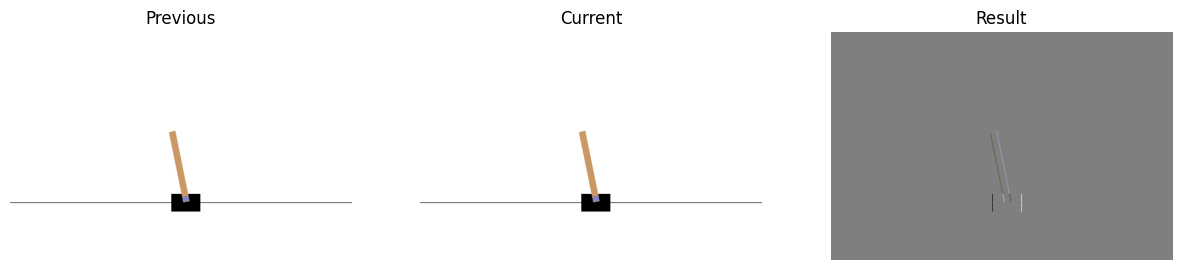

prev image shape: torch.Size([3, 400, 600])
curr image shape: torch.Size([3, 400, 600])
diff image shape: torch.Size([3, 400, 600])
batch shape: torch.Size([32, 3, 128, 128])


/usr/local/lib/python3.11/dist-packages/gym/envs/classic_control/cartpole.py:177: UserWarning: WARN: You are calling 'step()' even though this environment has already returned terminated = True. You should always call 'reset()' once you receive 'terminated = True' -- any further steps are undefined behavior.
  logger.warn(


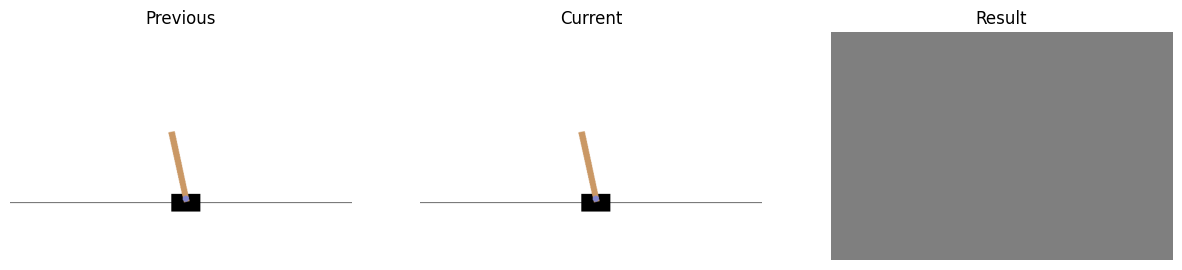

prev image shape: torch.Size([3, 400, 600])
curr image shape: torch.Size([3, 400, 600])
diff image shape: torch.Size([3, 400, 600])
batch shape: torch.Size([32, 3, 128, 128])


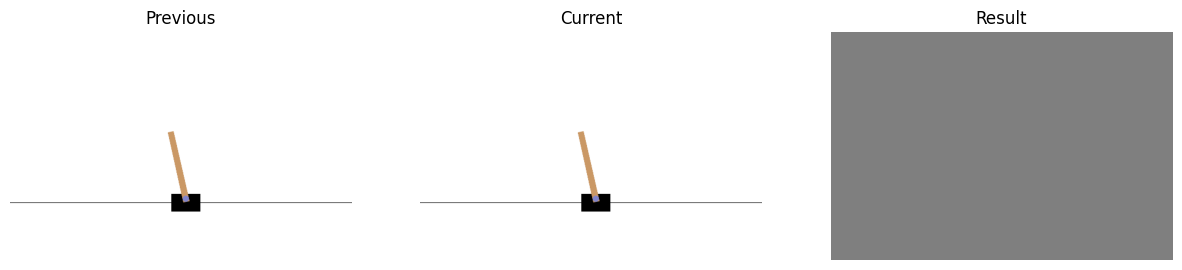

prev image shape: torch.Size([3, 400, 600])
curr image shape: torch.Size([3, 400, 600])
diff image shape: torch.Size([3, 400, 600])
batch shape: torch.Size([32, 3, 128, 128])


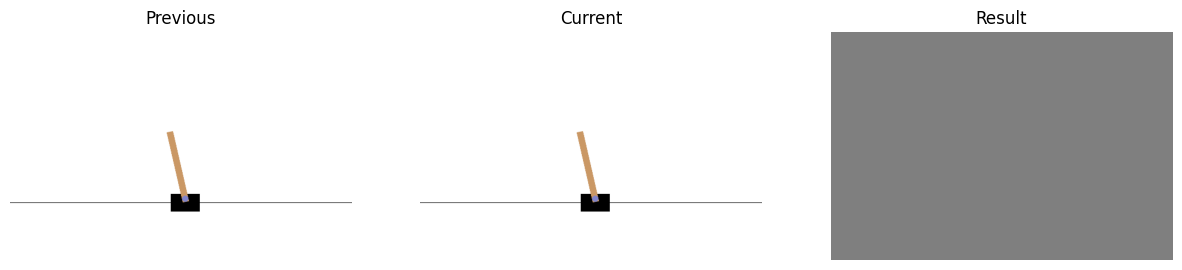

In [ ]:
# create env
env = gym.make("CartPole-v1", render_mode="rgb_array")

# action space
action_space = env.action_space
possible_actions = list(range(action_space.n))

# reward range
reward_range = env.reward_range

# infos
print(f"🚀 Environment Information:")
print(f"🎮 Possible Actions: {possible_actions}")
print(f"🏆 Reward Range: {reward_range}")

# reset env and get init obs
obs = env.reset()

# transform
im_size = 128
b_size = 32

batch_transform = transforms.Compose([
    transforms.ToPILImage(),
    transforms.Resize((im_size, im_size)),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.1),
    transforms.RandomAffine(degrees=15, translate=(0.1, 0.1), scale=(0.8, 1.2)),
    transforms.RandomGrayscale(p=0.1),
    transforms.GaussianBlur(kernel_size=5, sigma=(0.1, 2.0)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

# Run a certain number of episodes
for epi_idx in range(4):

    # one episode untill while loop is done
    done = False
    epi_len = 0
    while not done:
        if epi_len == 0:
            epi_len += 1
            prev_img_obs = get_img_obs(env)
            continue

        # count epi length
        epi_len += 1

        # use diff = img_obs(t) - img_obs(t-1)
        curr_img_obs = get_img_obs(env)
        img_diff = get_image_diff(curr_img_obs, prev_img_obs)
        prev_img_obs = curr_img_obs

        # get batch
        batch = get_batch_img_obs(obs_img=img_diff, b_size=b_size, transform=batch_transform)

        # debugging
        print(f"prev image shape: {prev_img_obs.shape}")
        print(f"curr image shape: {curr_img_obs.shape}")
        print(f"diff image shape: {img_diff.shape}")
        print(f"batch shape: {batch.shape}")

        # Select a random action
        action = env.action_space.sample()

        # take action and get next obs, reward, done, truncated
        obs, reward, done, _, info = env.step(action)
        img_obs = get_img_obs(env)

        # take next action
        env.render()

        # show obs img
        # show_img_obs(img_obs, rm_pre=True)
        show_three_images(prev_img_obs, curr_img_obs, img_diff, rm_pre=False)
        time.sleep(1)

env.close()

# Model: Vanilla Policy

In [ ]:
# Define model
class ResidualBlock(nn.Module):
    def __init__(self, in_ch):
        super(ResidualBlock, self).__init__()
        self.conv1 = nn.Conv2d(in_ch, in_ch, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(in_ch, in_ch, kernel_size=3, padding=1)

    def forward(self, x):
        x = F.relu(self.conv1(x))
        x = F.relu(self.conv2(x))
        return x

class PolicyResNet(nn.Module):
    def __init__(self, d_rate):
        super(PolicyResNet, self).__init__()
        self.conv1 = nn.Conv2d(3, 16, kernel_size=8, stride=2, padding=0)   # [B, 16, 61, 61] after conv1
        self.pool1 = nn.MaxPool2d(2, 2)                                     # [B, 16, 30, 30] after pool1

        self.residual_block = ResidualBlock(16)

        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, stride=2, padding=0)  # [B, 32, 15, 15] after conv2
        self.pool2 = nn.MaxPool2d(2, 2)                                     # [B, 32, 7, 7] after pool2
        self.fc_dim = 32 * 7 * 7
        self.fc1 = nn.Linear(self.fc_dim, 128)
        self.fc2 = nn.Linear(128, 64)
        self.fc3 = nn.Linear(64, 2)
        self.dropout = nn.Dropout(d_rate)

    def forward(self, x):
        x = self.conv1(x)
        x = F.relu(x)
        x = self.pool1(x)
        x = x + self.residual_block(x)
        x = self.dropout(x)

        x = self.conv2(x)
        x = F.relu(x)
        x = self.pool2(x)
        x = self.dropout(x)

        x = x.view(-1, self.fc_dim)
        x = self.fc1(x)
        x = F.relu(x)
        x = self.dropout(x)

        x = self.fc2(x)
        x = F.relu(x)
        x = self.dropout(x)

        x = self.fc3(x)
        return F.softmax(x, dim=-1)

    def sample_action(self, a_probs, epsilon):
        """ this function is for a single input"""
        n_actions = a_probs.shape[-1]
        if torch.rand(1).item() < epsilon:
            # ε-case: choose a random action uniformly.
            a = torch.randint(0, n_actions, (1,))
            prob = torch.clamp(a_probs[0, a.item()], min=1e-8, max=1e9)
            log_p = torch.log(prob).unsqueeze(0)
        else:
            # 1 - ε-case: sample from the policy distribution.
            p_dist = Categorical(a_probs)
            a = p_dist.sample()
            log_p = p_dist.log_prob(a)

        return a.item(), log_p

    def sample_batch_action(self, a_probs, epsilon):
        """ this function is for batchs of inputs"""
        b_size, n_actions = a_probs.shape

        # [True, False, True] => [Random, Policy, Random]
        eps_mask = torch.rand(b_size) < epsilon

        # Build Prob Dist on a_probs.
        p_dist = Categorical(a_probs)               # Think of it as a simulation of the Prob Dist of a_probs.
        a_sample = p_dist.sample()                  # Sample from Prob Dist.
        a_log_prob = p_dist.log_prob(a_sample)      # Just log of Prob.

        r_actions = torch.randint(0, n_actions, (b_size,))              # Random actions (epsilon).
        r_prob = a_probs[torch.arange(b_size), r_actions]               # Random prob.
        r_log_prob = torch.log(torch.clamp(r_prob, min=1e-8, max=1e9))  # Just log of Random Prob.

        a_idx = torch.where(eps_mask, r_actions, a_sample)
        log_p = torch.where(eps_mask, r_log_prob, a_log_prob)

        return a_idx, log_p


    def calculate_discounted_rewards(self, rewards, gamma, normalize=True):
        """ """
        G_t = []
        G = 0
        for r in reversed(rewards):
            G = r + gamma * G
            G_t.insert(0, G)

        if normalize:
            G_t = torch.tensor(G_t, dtype=torch.float32)
            G_t = (G_t - G_t.mean()) / (G_t.std() + 1e-9)
        return G_t

    def compute_policy_loss(self, log_probs, discounted_rewards):
        losses = []
        for log_p, G in zip(log_probs, discounted_rewards):
            losses.append(-log_p * G)

        loss = torch.stack(losses).sum()
        return loss

# test model
d_rate = 0.5
model = PolicyResNet(d_rate)

im_size = 128
im_ch = 3
b_size = 3


# simple simulation of RL training process
log_probs = []
rewards = []

for _ in range(4):
    x = torch.randn(b_size, im_ch, im_size, im_size)
    a_probs = model(x)

    a_idx, log_p = model.sample_batch_action(a_probs, epsilon=0.5)

    log_probs.extend(log_p)

    # for each idx in a_idx
    reward = 1
    rewards.extend([reward] * b_size)

rewards_to_go = model.calculate_discounted_rewards(rewards, gamma=0.9, normalize=False)

loss = model.compute_policy_loss(log_probs, rewards_to_go)

print(f"a_probs.shape: {a_probs.shape}")
print(f"a_idx.shape: {a_idx.shape}")
print(f"log_p.shape: {log_p.shape}")
print(f"rewads_to_go : {rewards_to_go}")
print(f"Loss: {loss.item()}")

a_probs.shape: torch.Size([3, 2])
a_idx.shape: torch.Size([3])
log_p.shape: torch.Size([3])
rewads_to_go : [7.175704635190001, 6.861894039100001, 6.5132155990000005, 6.12579511, 5.6953279000000006, 5.217031, 4.68559, 4.0951, 3.439, 2.71, 1.9, 1.0]
Loss: 38.32019805908203


# Training

In [ ]:
# learning config
lr = 1e-3
d_rate = 0.2
epsilon = 0.1
im_size = 128
im_ch = 3
b_size = 64

# RL config
n_episodes = 8000
n_epochs = 200
n_epi_per_epoch = n_episodes // n_epochs
n_eval_episode = n_epi_per_epoch

gamma = 0.98
threshold = 500

# model
agent = PolicyResNet(d_rate)

# optimizer
optimizer = optim.AdamW(agent.parameters(), lr=lr, weight_decay=1e-4) # optim.Adam(agent.parameters(), lr=lr)

# data augmentation
batch_transform = transforms.Compose([
    transforms.ToPILImage(),
    transforms.Resize((im_size, im_size)),
    transforms.ColorJitter(brightness=0.1, contrast=0.1, saturation=0.1, hue=0.05),
    transforms.RandomAffine(degrees=15, translate=(0.1, 0.1), scale=(0.8, 1.2)),
    transforms.RandomGrayscale(p=0.1),
    transforms.GaussianBlur(kernel_size=5, sigma=(0.1, 2.0)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

valid_transform = transforms.Compose([
    transforms.ToPILImage(),
    transforms.Resize((im_size, im_size)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

# set env with render_mode set to 'rgb_array' to allow proper rendering
env = gym.make("CartPole-v1", render_mode="rgb_array")

# init metrics
metrics = {
    "train_avg_rewards": [],
    "train_std_rewards": [],
    "train_avg_epi_lens": [],
    "train_acc": [],
    "eval_avg_rewards": [],
    "eval_std_rewards": [],
    "eval_avg_epi_len": [],
    "eval_acc": [],
}

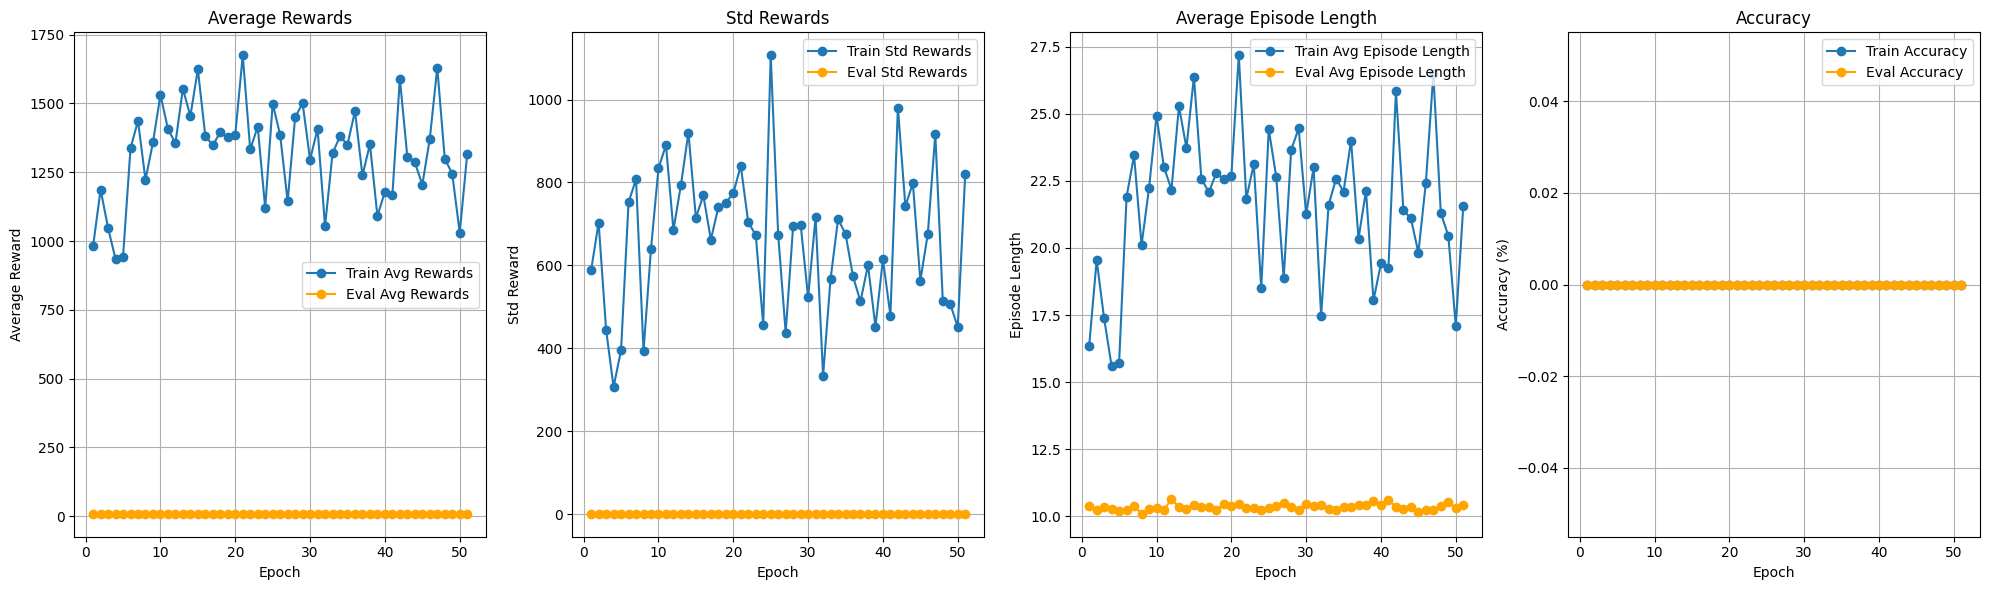

Episode: 0 | Total Reward: 1600.0 | Episode Length: 26


In [ ]:
# Epoch-based training loop
for epoch in range(n_epochs):
    n_success = 0
    list_of_tot_rewards = []
    list_of_epi_lens = []

    for episode in range(n_epi_per_epoch): # use range(2) for debugging

        # init state
        obs, info = env.reset()

        # Buffers
        log_probs = []
        rewards = []

        done = False
        epi_len = 0
        while not done:
            if epi_len == 0:
                epi_len += 1
                prev_img_obs = get_img_obs(env)
                continue

            # count epi length
            epi_len += 1

            # use diff = img_obs(t) - img_obs(t-1)
            curr_img_obs = get_img_obs(env)
            img_diff = get_image_diff(curr_img_obs, prev_img_obs)
            prev_img_obs = curr_img_obs

            # debugging
            # show_three_images(prev_img_obs, curr_img_obs, img_diff, rm_pre=True)
            # time.sleep(0.2)

            # create a batch
            img_diff = get_batch_img_obs(obs_img=img_diff, b_size=b_size, transform=batch_transform)

            # sample from policy
            a_probs = agent(img_diff)

            # sample an action
            a_idx, log_p = agent.sample_batch_action(a_probs, epsilon=epsilon)

            # Store the log probability of the action for later use in the loss
            log_probs.append(log_p)

            # let's take the most freq action
            fre_a_idx = torch.mode(a_idx).values.item()

            # Take the action in the environment
            obs, reward, done, truncated, info = env.step(fre_a_idx)
            rewards.extend([reward] * b_size)

            # If the episode was truncated = episode is done
            if truncated:
                done = True

        # discounted rewards
        rewards_to_go = agent.calculate_discounted_rewards(rewards, gamma, normalize=False)

        # loss
        loss = agent.compute_policy_loss(log_probs, rewards_to_go)

        # optimize
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        # Print the total reward every 50 episodes
        if episode % 100 == 0:
            print(f"Episode: {episode} | Total Reward: {sum(rewards)} | Episode Length: {epi_len}")

        # Collect training metrics per episode
        n_success += 1 if epi_len >= threshold else 0
        list_of_tot_rewards.append(sum(rewards))
        list_of_epi_lens.append(epi_len)

    # Compute training metrics for this epoch
    train_acc = (n_success / n_epi_per_epoch) * 100
    train_avg_reward = np.mean(list_of_tot_rewards)
    train_std_reward = np.std(list_of_tot_rewards)
    train_avg_epi_len = np.mean(list_of_epi_lens)

    # Evaluate the current policy
    eval_metrics = evaluate_cnn_diff_policy(agent=agent, env=env, n_eval_episode=n_eval_episode, threshold=threshold, transform=valid_transform)

    # Save metrics (using the exact keys you provided)
    metrics["train_acc"].append(train_acc)
    metrics["train_avg_rewards"].append(train_avg_reward)
    metrics["train_std_rewards"].append(train_std_reward)
    metrics["train_avg_epi_lens"].append(train_avg_epi_len)
    metrics["eval_acc"].append(eval_metrics["eval_acc"])
    metrics["eval_avg_rewards"].append(eval_metrics["eval_avg_rewards"])
    metrics["eval_std_rewards"].append(eval_metrics["eval_std_rewards"])
    metrics["eval_avg_epi_len"].append(eval_metrics["eval_avg_epi_len"])

    # Update live plot with the new metrics
    live_plot(metrics)

# Save the model weights and close the environment
torch.save(agent.state_dict(), "policy_net_cartpole.pth")
env.close()
print("Training complete. Model weights saved as 'policy_net_cartpole.pth'.")